# stage 1 — megan: need to do

 
1. Use the environment in environment.yml and the setup instructions in README.md.
2. Restart the kernel and run all cells from top to bottom.
3. Complete each comment-only response cell using your run's values and figures; use comments for written answers.
4. Save this notebook and share your notes and output folder with Sahil.

The saved outputs demonstrate a verified run; rerun to measure your own machine.
Your written responses are intentionally unfinished.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
from importlib.metadata import version
import platform
import time

ROOT = Path.cwd()

import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
from torchvision.datasets import MNIST

%matplotlib inline

CONFIG = {
    "seed": 42, "n_train": 2000, "n_val": 200, "n_test": 200,
    "image_size": 28, "retained_lines": 7, "central_lines": 3,
    "pca_ranks": [8, 16, 32], "ridge_values": [0.0, 0.0001, 0.01],
    "eight_image_steps": 1500, "eight_image_lr": 0.01,
}
DATA_DIR = ROOT / "data"
RUN_DIR = ROOT / "outputs" / "stage1" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR.mkdir(parents=True)
H = W = CONFIG["image_size"]
AXES = (-2, -1)
torch.set_num_threads(1)
torch.manual_seed(CONFIG["seed"])
print("device: CPU")
print("hardware:", platform.platform(), platform.machine())
print("output folder:", RUN_DIR.relative_to(ROOT))

device: CPU
hardware: macOS-26.0-arm64-arm-64bit arm64
output folder: outputs/stage1/20261017T194144_806900Z


## 1. MNIST and held-out subsets
Download into the local data folder if needed. Validation comes from the official
training pool; test evaluation uses the official test pool. Seeded indices are
saved. Dividing byte intensities by 255 fixes [0, 1] without fitting normalization
to test data.

train / validation / test: 2000 200 200
intensity range: 0.0 1.0


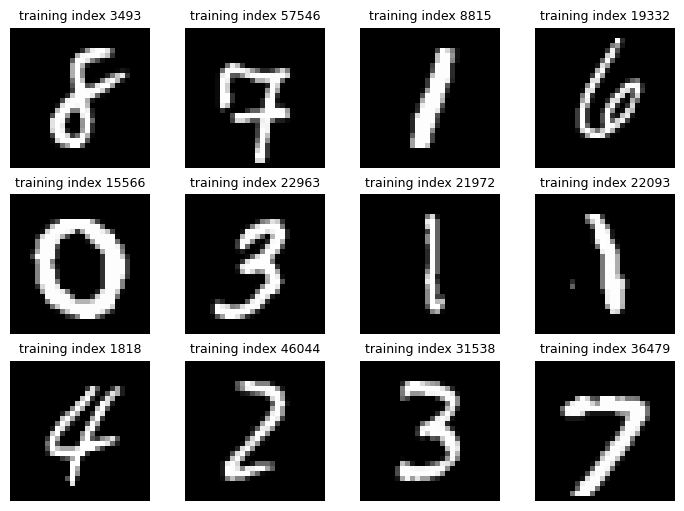

In [2]:
training_pool = MNIST(root=str(DATA_DIR), train=True, download=True)
test_pool = MNIST(root=str(DATA_DIR), train=False, download=True)
rng = np.random.default_rng(CONFIG["seed"])
order = rng.permutation(len(training_pool))
train_ids = order[:CONFIG["n_train"]]
val_ids = order[CONFIG["n_train"]:CONFIG["n_train"] + CONFIG["n_val"]]
test_ids = rng.permutation(len(test_pool))[:CONFIG["n_test"]]
assert set(train_ids).isdisjoint(set(val_ids))
assert len(train_ids) >= max(CONFIG["pca_ranks"]) + 1 and len(train_ids) >= 8
train = training_pool.data[train_ids].numpy().astype(np.float64) / 255.0
val = training_pool.data[val_ids].numpy().astype(np.float64) / 255.0
test = test_pool.data[test_ids].numpy().astype(np.float64) / 255.0
assert train.shape == (CONFIG["n_train"], H, W)
assert np.isfinite(train).all() and train.min() >= 0 and train.max() <= 1
print("train / validation / test:", len(train), len(val), len(test))
print("intensity range:", train.min(), train.max())
fig, axes = plt.subplots(3, 4, figsize=(7, 5), layout="constrained")
for ax, image, index in zip(axes.flat, train[:12], train_ids[:12]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"training index {index}", fontsize=9)
    ax.axis("off")
plt.show()

### need to do 1 — data note
**input:** the split counts, intensity range, and sample digit grid above.

1. Record the dataset, image size, training/validation/test counts, and intensity range.
2. Check the digit grid for blank or incorrectly scaled images.
3. Explain where the validation examples come from and how the test examples are kept separate.

**done when:** the counts match your run and your notes describe the split and any visible data issue.

In [ ]:
# need to do: record the dataset, split counts, intensity range, and your data notes.

## 2. complex Fourier measurements and operator checks
Use centered, orthonormal FFTs on spatial axes only. The paired inverse uses the
same shifts around ifft2. The mask retains seven complete lines, including three
central lines: 196 of 784 complex coefficients (25%). No measurement noise is added.

Retain both real and imaginary measurements. For real images the adjoint in the
real inner product is Re(F_inv(M y)). Check round-trip, DC, off-center impulse phase,
and adjoint agreement before interpreting reconstructed images.

In [3]:
def fft2c(images):
    return np.fft.fftshift(
        np.fft.fft2(np.fft.ifftshift(images, axes=AXES), axes=AXES, norm="ortho"), axes=AXES)

def ifft2c(kspace):
    return np.fft.fftshift(
        np.fft.ifft2(np.fft.ifftshift(kspace, axes=AXES), axes=AXES, norm="ortho"), axes=AXES)

mask_rng = np.random.default_rng(CONFIG["seed"] + 1)
start = H // 2 - CONFIG["central_lines"] // 2
central = np.arange(start, start + CONFIG["central_lines"])
outside = np.setdiff1d(np.arange(H), central)
extra = mask_rng.choice(outside, CONFIG["retained_lines"] - len(central), replace=False)
sampled_rows = np.sort(np.concatenate([central, extra]))
mask = np.zeros((H, W), dtype=bool)
mask[sampled_rows, :] = True
assert mask.sum() == CONFIG["retained_lines"] * W

check_rng = np.random.default_rng(CONFIG["seed"] + 2)
complex_batch = check_rng.normal(size=(2, H, W)) + 1j * check_rng.normal(size=(2, H, W))
dc_expected = np.zeros((H, W), dtype=complex)
dc_expected[H // 2, W // 2] = np.sqrt(H * W)
impulse = np.zeros((H, W))
dx, dy = 3, -5
impulse[H // 2 + dx, W // 2 + dy] = 1
u, v = np.meshgrid(np.arange(H) - H // 2, np.arange(W) - W // 2, indexing="ij")
phase_expected = np.exp(-2j * np.pi * (u * dx / H + v * dy / W)) / np.sqrt(H * W)
x_probe = check_rng.normal(size=(H, W))
y_probe = check_rng.normal(size=(H, W)) + 1j * check_rng.normal(size=(H, W))
lhs = np.vdot(mask * fft2c(x_probe), y_probe).real
rhs = np.vdot(x_probe, ifft2c(mask * y_probe).real).real
fourier_checks = {
    "complex_batch_roundtrip_max_error": float(np.max(np.abs(ifft2c(fft2c(complex_batch)) - complex_batch))),
    "constant_dc_max_error": float(np.max(np.abs(fft2c(np.ones((H, W))) - dc_expected))),
    "off_center_impulse_phase_max_error": float(np.max(np.abs(fft2c(impulse) - phase_expected))),
    "real_domain_adjoint_absolute_error": float(abs(lhs - rhs)),
}
for name, value in fourier_checks.items():
    print(f"{name}: {value:.3e}")
assert max(fourier_checks.values()) < 1e-10, "Fourier convention check failed."
print("sampled rows:", sampled_rows.tolist())
print(f"measured: {int(mask.sum())}/{H * W} complex coefficients ({mask.mean():.0%})")

complex_batch_roundtrip_max_error: 1.831e-15
constant_dc_max_error: 3.553e-15
off_center_impulse_phase_max_error: 1.550e-16
real_domain_adjoint_absolute_error: 4.441e-15
sampled rows: [1, 9, 11, 13, 14, 15, 18]
measured: 196/784 complex coefficients (25%)


### need to do 2 — explain the measurements
**input:** the Fourier-check output and sampled-coefficient count above.

1. Record how many coefficients were kept and the percentage of the full image.
2. In three short sentences, explain what is measured, why missing measurements make recovery ambiguous, and how a prior helps.
3. Explain why discarding the imaginary Fourier component would change the problem.

**done when:** you can explain the task to Sahil and all four prepared Fourier checks pass.

In [ ]:
# need to do: record the sampled fraction and explain the measurements and the prior.

## 3. fit PCA, measure training time, and choose settings
The prior is x = mean + U z. Fit the mean and principal directions on training
images only. Recover real coefficients by minimizing the complex measurement
residual squared plus ridge times the squared coefficient norm. Stacking real
and imaginary equations preserves the full measurement information.

Fit once at the maximum rank, choose rank/ridge by validation PSNR, then lock them.
PCA fitting is a closed-form training run; its timing excludes validation and
reconstruction.

In [4]:
with threadpool_limits(limits=1):
    fit_start = time.perf_counter()
    pca = PCA(n_components=max(CONFIG["pca_ranks"]), svd_solver="randomized", random_state=CONFIG["seed"])
    pca.fit(train.reshape(len(train), -1))
    pca_training_seconds = time.perf_counter() - fit_start

mean_image = pca.mean_.reshape(H, W)
mean_measured = fft2c(mean_image)[mask]
basis_measured = fft2c(pca.components_.reshape(-1, H, W))[:, mask].T

def psnr(reference, reconstruction):
    mse = np.mean((reference - reconstruction) ** 2, axis=(-2, -1))
    with np.errstate(divide="ignore"):
        return 10 * np.log10(1.0 / mse)

def principal_reconstruct(measurements, rank, ridge):
    design_complex = basis_measured[:, :rank]
    design = np.concatenate([design_complex.real, design_complex.imag], axis=0)
    centered = measurements - mean_measured
    target = np.concatenate([centered.real, centered.imag], axis=1).T
    if ridge > 0:
        design = np.vstack([design, np.sqrt(ridge) * np.eye(rank)])
        target = np.vstack([target, np.zeros((rank, target.shape[1]))])
    with threadpool_limits(limits=1):
        coefficients = np.linalg.lstsq(design, target, rcond=1e-10)[0].T
    return (pca.mean_ + coefficients @ pca.components_[:rank]).reshape(-1, H, W)

val_measurements = fft2c(val)[:, mask]
validation_rows = []
for rank in CONFIG["pca_ranks"]:
    for ridge in CONFIG["ridge_values"]:
        reconstructed = principal_reconstruct(val_measurements, rank, ridge)
        validation_rows.append({"rank": rank, "ridge": ridge,
                                "mean_validation_psnr_db": float(psnr(val, reconstructed).mean())})
best = max(validation_rows, key=lambda row: row["mean_validation_psnr_db"])
selected_rank, selected_ridge = best["rank"], best["ridge"]
print(f"PCA training: {pca_training_seconds:.6f} s on CPU ({len(train)} images)")
print("validation-selected settings:", best)
print(f"retained training variance: {pca.explained_variance_ratio_[:selected_rank].sum():.2%}")

PCA training: 0.017018 s on CPU (2000 images)
validation-selected settings: {'rank': 32, 'ridge': 0.01, 'mean_validation_psnr_db': 17.23682719667602}
retained training variance: 74.67%


## 4. locked test comparison
Both methods get identical measurements. Zero-filling sets missing coefficients
to zero and applies the paired inverse FFT. Keep its complex result and evaluate
the real component for this real-image task. PCA also produces real images.

PSNR uses fixed data range 1 on raw reconstructions, with no clipping or per-image
rescaling. The first seeded test index is the displayed example; it is not chosen
for a favorable score.

In [5]:
test_kspace = fft2c(test)
test_measurements = test_kspace[:, mask]
start_time = time.perf_counter()
zero_complex = ifft2c(test_kspace * mask)
zero_filled = zero_complex.real
zero_seconds = time.perf_counter() - start_time
start_time = time.perf_counter()
principal = principal_reconstruct(test_measurements, selected_rank, selected_ridge)
recovery_seconds = time.perf_counter() - start_time

zero_psnr, pca_psnr = psnr(test, zero_filled), psnr(test, principal)
print(f"test mean PSNR — zero-filling: {zero_psnr.mean():.3f} dB; PCA: {pca_psnr.mean():.3f} dB")
print(f"PCA beats zero-filling on {int((pca_psnr > zero_psnr).sum())}/{len(test)} test cases")
print(f"all-test reconstruction — zero-fill: {zero_seconds:.6f} s; PCA: {recovery_seconds:.6f} s")

test mean PSNR — zero-filling: 15.817 dB; PCA: 17.374 dB
PCA beats zero-filling on 160/200 test cases
all-test reconstruction — zero-fill: 0.001793 s; PCA: 0.002656 s


### need to do 3 — record the reconstruction result
**input:** the held-out PSNR output above and the submission figure in section 7.
PSNR measures similarity to the reference; higher is better when the data range is fixed.

1. Record mean test PSNR for zero-filling and PCA, plus the selected PCA rank and ridge value.
2. Compare the reference and both reconstructions in the figure. Describe one visible improvement or failure.
3. Explain whether the mean result means PCA wins on every individual digit.

**done when:** the numbers come from your run and the description agrees with the displayed example.

In [ ]:
# need to do: record the PSNR values and explain a reconstruction improvement or failure.

## 5. required check: train on eight images
A one-step PCA fit does not show an optimization curve. Train a randomly
initialized rank-8 linear autoencoder plus the eight-image mean on eight training
examples. Eight centered examples span at most seven directions, so this
diagnostic has enough capacity. Use reconstruction MSE without regularization;
do not initialize with the PCA solution.

This checks the training path, not held-out generalization. The diagnostic
near-zero threshold is 1e-5 on [0, 1] intensities.

In [6]:
torch.manual_seed(CONFIG["seed"] + 3)
eight_images = torch.tensor(train[:8].reshape(8, -1), dtype=torch.float64)
eight_mean = eight_images.mean(dim=0, keepdim=True)
eight_centered = eight_images - eight_mean
eight_model = torch.nn.Sequential(
    torch.nn.Linear(H * W, 8, bias=False),
    torch.nn.Linear(8, H * W, bias=False),
).double()
optimizer = torch.optim.Adam(eight_model.parameters(), lr=CONFIG["eight_image_lr"])
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[500, 1000], gamma=0.2)

def eight_mse():
    return ((eight_model(eight_centered) - eight_centered) ** 2).mean()

with torch.no_grad():
    initial_eight_loss = float(eight_mse())
eight_loss_rows = [{"step": 0, "mse": initial_eight_loss}]
start_time = time.perf_counter()
for step in range(1, CONFIG["eight_image_steps"] + 1):
    optimizer.zero_grad(set_to_none=True)
    loss = eight_mse()
    loss.backward()
    optimizer.step()
    scheduler.step()
    if step % 10 == 0 or step == CONFIG["eight_image_steps"]:
        with torch.no_grad():
            eight_loss_rows.append({"step": step, "mse": float(eight_mse())})
eight_seconds = time.perf_counter() - start_time
final_eight_loss = eight_loss_rows[-1]["mse"]
eight_threshold = 1e-5
print(f"8-image MSE: {initial_eight_loss:.9e} -> {final_eight_loss:.9e}")
print(f"8-image training: {eight_seconds:.6f} s for {CONFIG['eight_image_steps']} full-batch epochs")
assert final_eight_loss < eight_threshold, "8-image overfit check failed; inspect optimization."

8-image MSE: 6.184424499e-02 -> 3.344632386e-11
8-image training: 0.179541 s for 1500 full-batch epochs


### need to do 4 — interpret the eight-image check
**input:** the initial/final MSE and training time above; the loss curve in section 7.
MSE is the average squared pixel error; lower is better.

1. Record initial MSE, final MSE, and elapsed training time with units.
2. State whether the loss gets near zero and identify the supporting curve.
3. Explain why fitting eight training images does not establish good reconstruction of held-out images.

**done when:** you have the measured values and can explain the purpose and limit of this check.

In [ ]:
# need to do: record both losses and training time; explain what the eight-image check shows.

## 6. required check: one gradient against finite differences
Check one real coefficient of the actual complex Fourier reconstruction objective
at a non-optimal vector. Use float64 and centered finite differences. Select the
largest automatic derivative to avoid a trivial near-zero check. This uses a
training image, independently of test evaluation.

In [7]:
mean_t = torch.tensor(mean_image, dtype=torch.float64)
basis_t = torch.tensor(pca.components_[:selected_rank].T, dtype=torch.float64)
mask_t = torch.tensor(mask)
measurement_t = torch.tensor(fft2c(train[0])[mask], dtype=torch.complex128)

def torch_fft2c(image):
    return torch.fft.fftshift(
        torch.fft.fft2(torch.fft.ifftshift(image, dim=AXES), dim=AXES, norm="ortho"), dim=AXES)

def reconstruction_objective(z):
    image = mean_t + (basis_t @ z).reshape(H, W)
    residual = torch_fft2c(image)[mask_t] - measurement_t
    return residual.abs().square().sum() + selected_ridge * z.square().sum()

torch.manual_seed(CONFIG["seed"] + 4)
z = (0.3 * torch.randn(selected_rank, dtype=torch.float64)).requires_grad_()
gradient = torch.autograd.grad(reconstruction_objective(z), z)[0]
coordinate = int(gradient.abs().argmax())
epsilon = 1e-5
perturbation = torch.zeros_like(z)
perturbation[coordinate] = epsilon
with torch.no_grad():
    finite_difference = float((reconstruction_objective(z + perturbation) - reconstruction_objective(z - perturbation)) / (2 * epsilon))
automatic_gradient = float(gradient[coordinate])
absolute_error = abs(automatic_gradient - finite_difference)
relative_error = absolute_error / max(abs(automatic_gradient), abs(finite_difference), 1e-12)
print(f"coordinate: {coordinate}; epsilon: {epsilon:.1e}")
print(f"automatic gradient:       {automatic_gradient:.12e}")
print(f"finite-difference value: {finite_difference:.12e}")
print(f"absolute / relative error: {absolute_error:.3e} / {relative_error:.3e}")
assert np.isclose(automatic_gradient, finite_difference, rtol=1e-5, atol=1e-7), "Gradient check failed."

coordinate: 1; epsilon: 1.0e-05
automatic gradient:       -4.041961359738e+00
finite-difference value: -4.041961359746e+00
absolute / relative error: 8.910e-12 / 2.204e-12


### need to do 5 — record the gradient check
**input:** the two gradients, coordinate, finite-difference step, and comparison error above.

1. Record both gradient values, the coordinate, the step size, and the relative error.
2. Explain in one sentence why agreement is useful: two methods estimate the same local loss derivative.
3. Record the PCA fitting time from section 3 and the CPU/machine used. Keep it separate from eight-image training time.

**done when:** both gradient values and both training-run times are recorded from your own machine.

In [ ]:
# need to do: record both gradients, their comparison, and the separate training-run times.

## 7. one submission figure
Both methods share fixed intensity display limits, and the error maps share one
error scale. Lower panels show the required training curve, gradient numbers, and
measured training times. NPZ/JSON outputs retain the unedited numerical evidence.

saved: outputs/stage1/20261017T194144_806900Z/stage1_figure.png


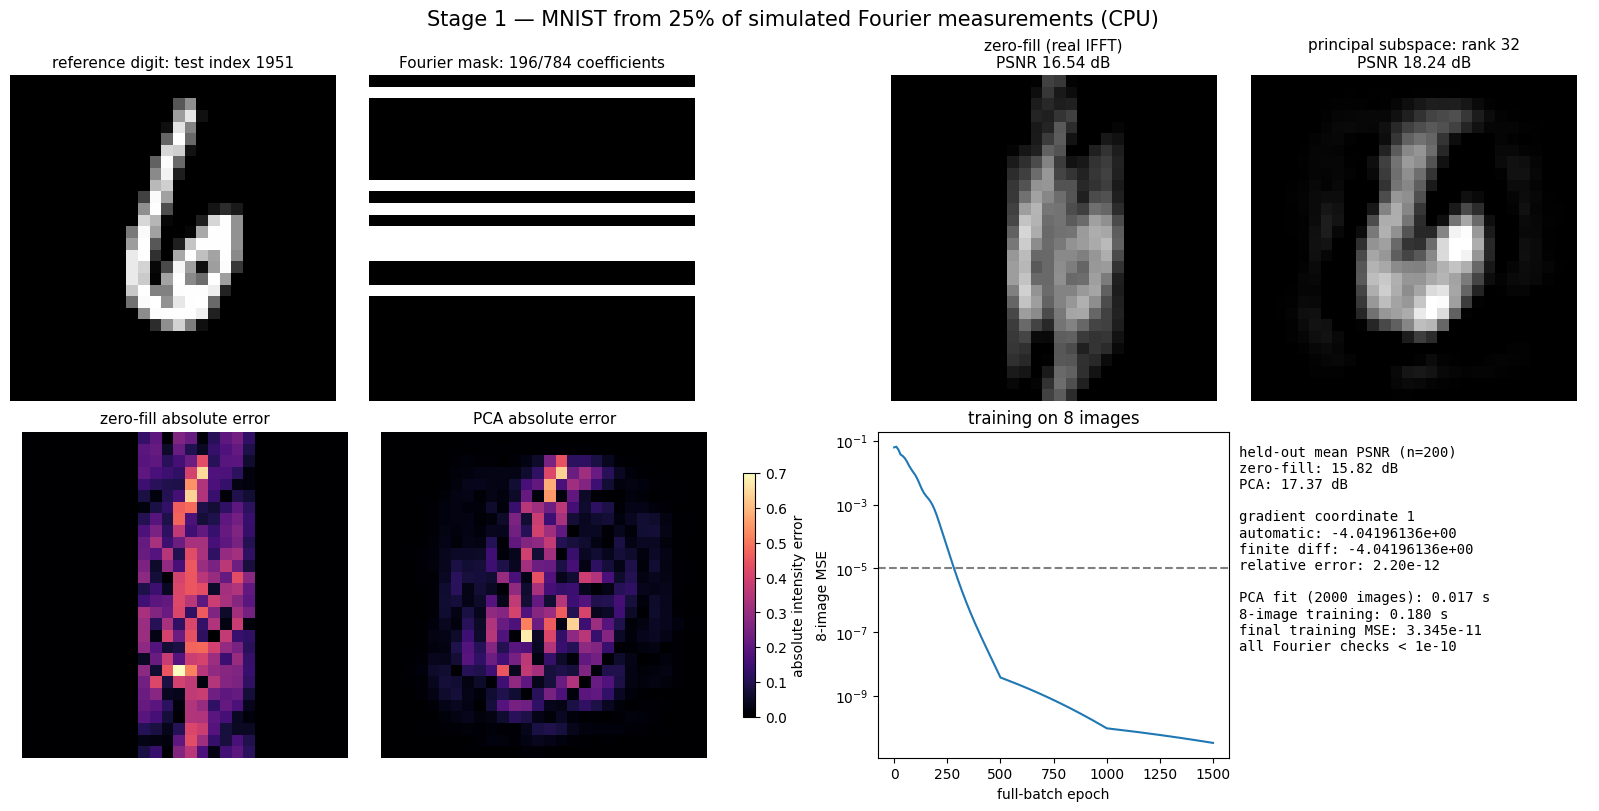

In [8]:
j = 0
fig, axes = plt.subplots(2, 4, figsize=(16, 8), layout="constrained")
images = [test[j], mask, zero_filled[j], principal[j]]
titles = [
    f"reference digit: test index {test_ids[j]}",
    f"Fourier mask: {mask.sum()}/{H * W} coefficients",
    f"zero-fill (real IFFT)\nPSNR {zero_psnr[j]:.2f} dB",
    f"principal subspace: rank {selected_rank}\nPSNR {pca_psnr[j]:.2f} dB",
]
for ax, image, title in zip(axes[0], images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
error_limit = max(float(np.max(np.abs(test[j] - zero_filled[j]))),
                  float(np.max(np.abs(test[j] - principal[j]))))
for ax, rec, title in zip(axes[1, :2], [zero_filled, principal], ["zero-fill absolute error", "PCA absolute error"]):
    error_plot = ax.imshow(np.abs(test[j] - rec[j]), cmap="magma", vmin=0, vmax=error_limit)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
fig.colorbar(error_plot, ax=list(axes[1, :2]), shrink=0.75, label="absolute intensity error")
ax = axes[1, 2]
ax.semilogy([r["step"] for r in eight_loss_rows], [r["mse"] for r in eight_loss_rows])
ax.axhline(eight_threshold, color="gray", linestyle="--")
ax.set(xlabel="full-batch epoch", ylabel="8-image MSE", title="training on 8 images")
axes[1, 3].axis("off")
evidence = (
    f"held-out mean PSNR (n={len(test)})\n"
    f"zero-fill: {zero_psnr.mean():.2f} dB\nPCA: {pca_psnr.mean():.2f} dB\n\n"
    f"gradient coordinate {coordinate}\n"
    f"automatic: {automatic_gradient:.8e}\nfinite diff: {finite_difference:.8e}\n"
    f"relative error: {relative_error:.2e}\n\n"
    f"PCA fit ({len(train)} images): {pca_training_seconds:.3f} s\n"
    f"8-image training: {eight_seconds:.3f} s\n"
    f"final training MSE: {final_eight_loss:.3e}\n"
    f"all Fourier checks < 1e-10"
)
axes[1, 3].text(0, 0.96, evidence, va="top", fontsize=10, family="monospace")
fig.suptitle("Stage 1 — MNIST from 25% of simulated Fourier measurements (CPU)", fontsize=15)
fig.savefig(RUN_DIR / "stage1_figure.png", dpi=160)
plt.show()
print("saved:", (RUN_DIR / "stage1_figure.png").relative_to(ROOT))

### need to do 6 — finish part of the submission
**input:** the complete figure above and the results you recorded.

1. Write a short caption naming MNIST, simulated Fourier measurements, the sampled fraction, and the comparison shown.
2. Write your own one-sentence expected difficulty. I will contribute the second sentence; the combined submission should contain exactly two.
3. Add a dated contribution entry describing what you ran, inspected, and learned.
4. Review the figure, checks, and timings together before submitting.



**done when:** the figure and required evidence are ready, the two sentences are your team's own, and your individual contribution is recorded.

In [ ]:
# need to do: write the caption, two difficulty sentences with Sahil, and your contribution entry.

## 8. save measured evidence
The run folder contains the submission figure, a small results JSON, raw arrays
and split indices, and the fitted models. Previous run folders are kept.
Timings exclude download, imports, and plotting; rerun on the intended machine.

### draft: two expected-difficulty sentences
The hardest part will be preserving a small inserted feature when the learned
prior favors more common image structure. We also expect balancing the score
prior with measurement consistency to require careful diagnosis as the sampling
noise level changes.

Review these two sentences together before submission.

In [9]:
summary = {
    "dataset": "MNIST", "config": CONFIG,
    "selected_rank": selected_rank, "selected_ridge": selected_ridge,
    "sampled_rows": sampled_rows.tolist(), "sampled_fraction": float(mask.mean()),
    "fft": "centered, norm=ortho, axes=(-2,-1); no measurement noise",
    "psnr": "data_range=1; raw real reconstruction; no clipping",
    "mean_test_psnr_db": {"zero_fill": float(zero_psnr.mean()), "pca": float(pca_psnr.mean())},
    "fourier_checks": fourier_checks,
    "gradient_check": {"coordinate": coordinate, "epsilon": epsilon,
        "automatic_gradient": automatic_gradient, "finite_difference_gradient": finite_difference,
        "absolute_error": absolute_error, "relative_error": relative_error},
    "eight_image_check": {"initial_mse": initial_eight_loss, "final_mse": final_eight_loss},
    "timing_seconds": {"pca_training_run": pca_training_seconds, "eight_image_training_run": eight_seconds,
        "zero_fill_all_test": zero_seconds, "pca_recovery_all_test": recovery_seconds},
    "hardware": {"platform": platform.platform(), "machine": platform.machine(), "device": "CPU"},
    "versions": {name: version(name) for name in ["numpy", "matplotlib", "scikit-learn", "torch", "torchvision"]},
    "python": platform.python_version(),
}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
np.savez_compressed(RUN_DIR / "run_data.npz",
    train_indices=train_ids, validation_indices=val_ids, test_indices=test_ids, mask=mask,
    reference=test, measurements=test_measurements, zero_filled_complex=zero_complex,
    principal_subspace=principal, zero_fill_psnr=zero_psnr, pca_psnr=pca_psnr,
    eight_image_loss=np.array([[r["step"], r["mse"]] for r in eight_loss_rows]),
    validation_scores=np.array([[r["rank"], r["ridge"], r["mean_validation_psnr_db"]] for r in validation_rows]))
np.savez_compressed(RUN_DIR / "pca_checkpoint.npz", mean=pca.mean_, components=pca.components_,
    explained_variance=pca.explained_variance_, selected_rank=selected_rank, selected_ridge=selected_ridge)
torch.save({"state_dict": eight_model.state_dict(), "mean": eight_mean}, RUN_DIR / "eight_image_model.pt")
(RUN_DIR.parent / "latest_run.txt").write_text(str(RUN_DIR.relative_to(ROOT)) + "\n")
print("saved figure, results, splits, and models:", RUN_DIR.relative_to(ROOT))

saved figure, results, splits, and models: outputs/stage1/20261017T194144_806900Z


## partner handoff
Open the saved figure and summary.json. Record both gradient numbers, the check
outcomes, your local timing, and an observed reconstruction improvement/failure.
Explain why fitting eight training images does not guarantee held-out recovery,
and why dropping imaginary Fourier components changes the task. Review the two
difficulty sentences together and keep separate contribution logs.

Sources: [MNIST loader](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html),
[NumPy FFT](https://numpy.org/doc/stable/reference/generated/numpy.fft.fft2.html),
the Stage 1 submission checklist in Paper_1_and_Stage_1_Guide.pdf.

Partner can use stage1_partner.ipynb for the same runnable code with need to do prompts.